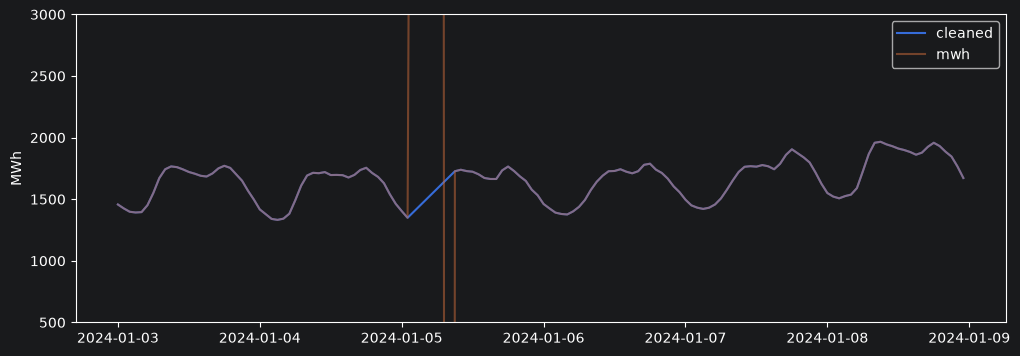

Naive Error Means:
24 hour:66.9703129657228
168 hour: 113.5701043219076
Naive Error Percentage Means:
24 hour: 4.49629680094984
168 hour: 7.500697182845776


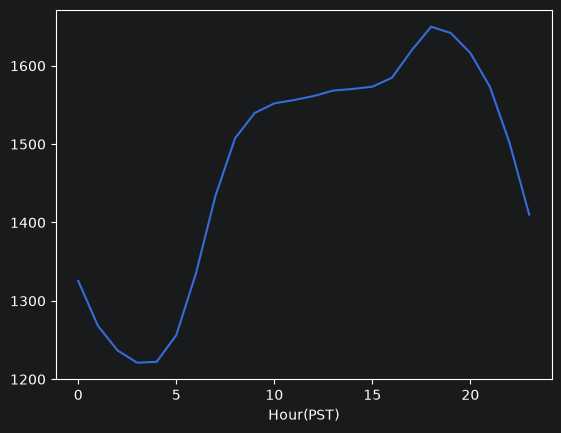

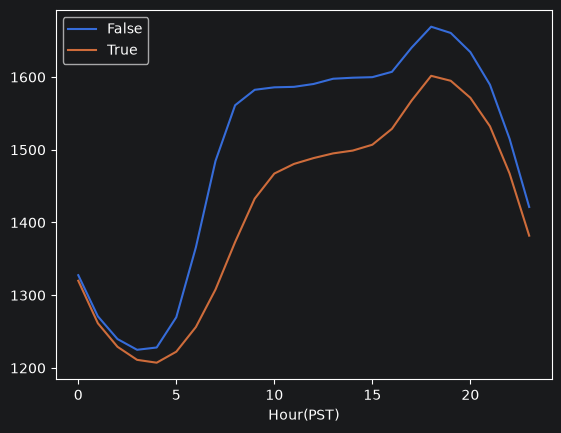

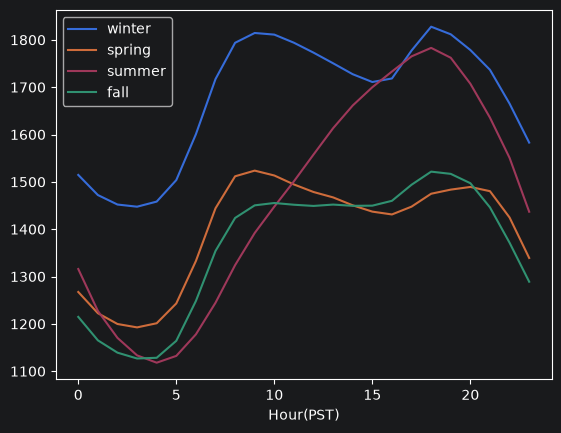

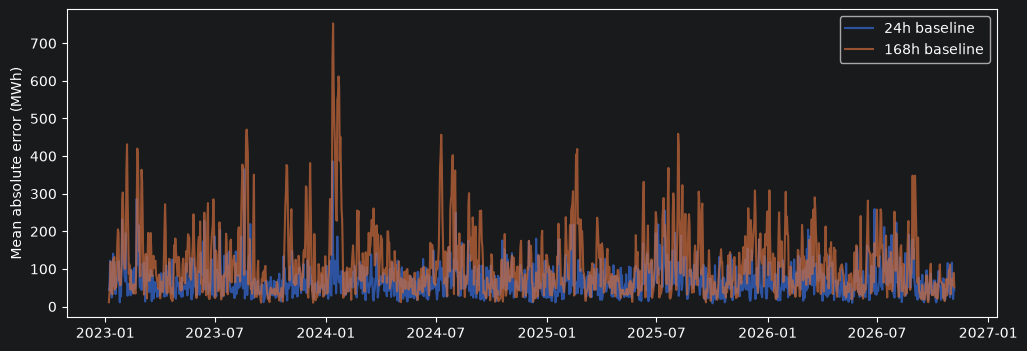

In [2]:
import pandas
from IPython.core.pylabtools import figsize
from sqlalchemy import text
from forecast.db.session import get_engine
import matplotlib.pyplot as plt

#
#

def calculate_hourly_means(df):
    return df.groupby(df.index.hour)["clean"].mean()

def is_data_in_months(df, *args):
    return df[df.index.month.isin(list(args))]

query = text("select ts_utc, mwh from demand_hourly where ba = \'AVA\' order by ts_utc asc")

demand = pandas.read_sql(query, get_engine(), parse_dates = ["ts_utc"]).set_index("ts_utc")

#
#

#Data cleaning & linear interpolation, along with plotting all data with interpolation
bad = ((demand["mwh"] < 0) | (demand["mwh"] > 5000))
demand["clean"] = demand["mwh"].mask(bad).interpolate(method ="time")
demand["imputable"] = bad
demand.index = demand.index.tz_convert("America/Los_Angeles")

window = slice("2024-01-03", "2024-01-08")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(demand.loc[window].index, demand.loc[window, "clean"], label="cleaned")
ax.plot(demand.loc[window].index, demand.loc[window, "mwh"], label="mwh", alpha=0.5)
ax.set_ylabel("MWh")
ax.legend()
ax.set_ylim(500, 3000)
plt.show()

#
#

#Plots hourly means over all data
hourly_means = calculate_hourly_means(demand).rename_axis("Hour(PST)")
hourly_means.plot()

#
#

#Weekend calculations
is_weekend = demand.index.day_of_week >= 5
weekend_and_weekday_means = demand.groupby([is_weekend, demand.index.hour])["clean"].mean().unstack(0).rename_axis("Hour(PST)")
weekend_and_weekday_means.plot()

#
#

#Seasonal calculations
winter = is_data_in_months(demand, 1, 2, 12)
spring = is_data_in_months(demand, 3, 4, 5)
summer = is_data_in_months(demand, 6, 7, 8)
fall = is_data_in_months(demand, 9, 10, 11)
seasonal_means = pandas.concat([calculate_hourly_means(winter), calculate_hourly_means(spring), calculate_hourly_means(summer), calculate_hourly_means(fall)], axis = 1, keys = ["winter", "spring", "summer", "fall"]).rename_axis("Hour(PST)")
seasonal_means.plot()

#
#

#Naive error calculations
d =demand.copy()
d["prev_24"] = d["clean"].shift(24)
d["prev_168"] = d["clean"].shift(168)

valid168 = d["prev_168"].notna() & ~d["imputable"] & ~(d["imputable"].shift(168).fillna(True).astype(bool))
valid24 = d["prev_24"].notna() & ~d["imputable"] & ~(d["imputable"].shift(24).fillna(True).astype(bool))
valid = valid24 & valid168
#Calculate and print MAE for naive absolute error going back a week or a day as the baseline. Does the same for the MAPE; prints them out
naive_err_24 = (d.loc[valid, "clean"] - d.loc[valid, "prev_24"]).abs()
naive_err_168 = (d.loc[valid, "clean"] - d.loc[valid, "prev_168"]).abs()
print("Naive Error Means:")
print(f"24 hour:{naive_err_24.mean()}")
print(f"168 hour: {naive_err_168.mean()}")
naive_mape_24 = (naive_err_24 / d.loc[valid, "clean"]).mean() * 100
naive_mape_168 = (naive_err_168 / d.loc[valid, "clean"]).mean() * 100
print("Naive Error Percentage Means:")
print(f"24 hour: {naive_mape_24}")
print(f"168 hour: {naive_mape_168}")

#
#

#Plots mean absolute errors by day
daily_24 = naive_err_24.resample("D").mean()
daily_168 = naive_err_168.resample("D").mean()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily_24.index, daily_24, label="24h baseline", alpha=0.7)
ax.plot(daily_168.index, daily_168, label="168h baseline", alpha=0.7)
ax.set_ylabel("Mean absolute error (MWh)")
ax.legend()
plt.show()


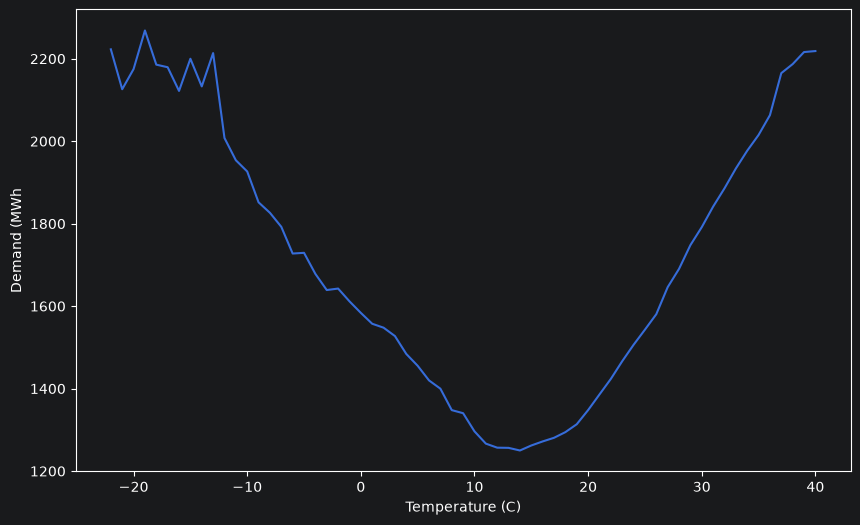

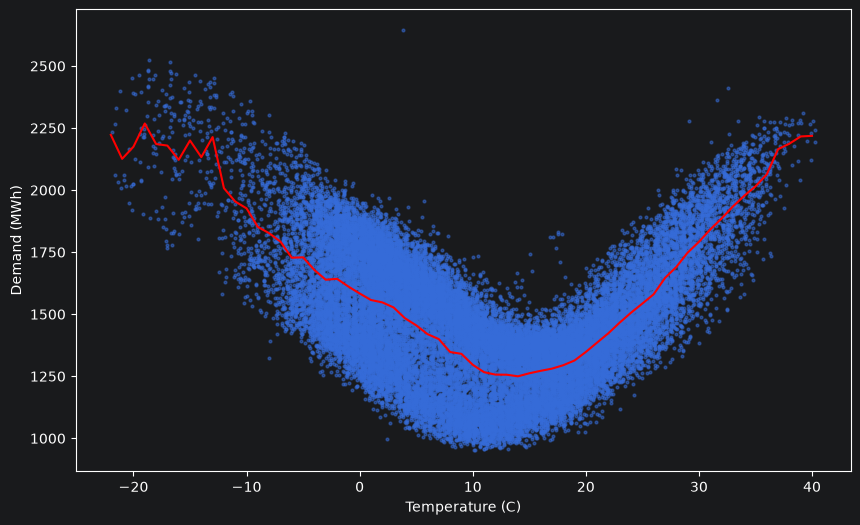

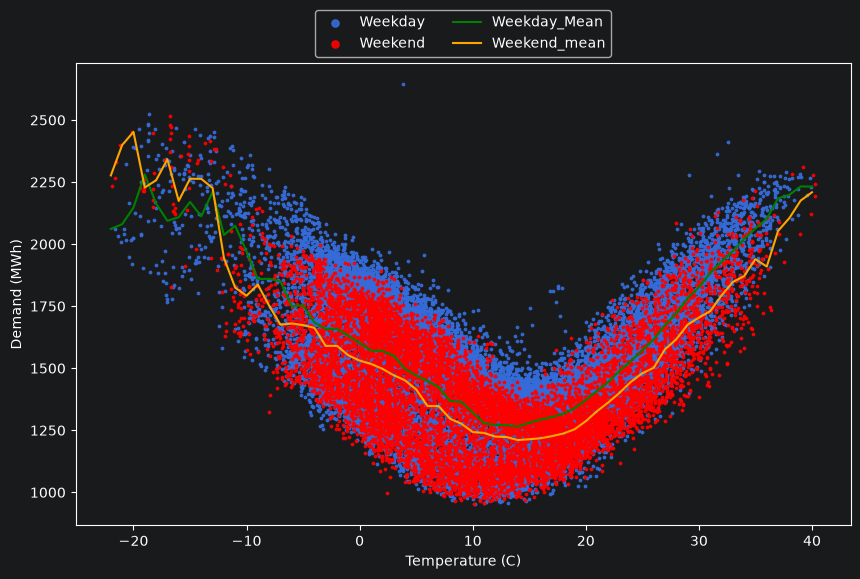

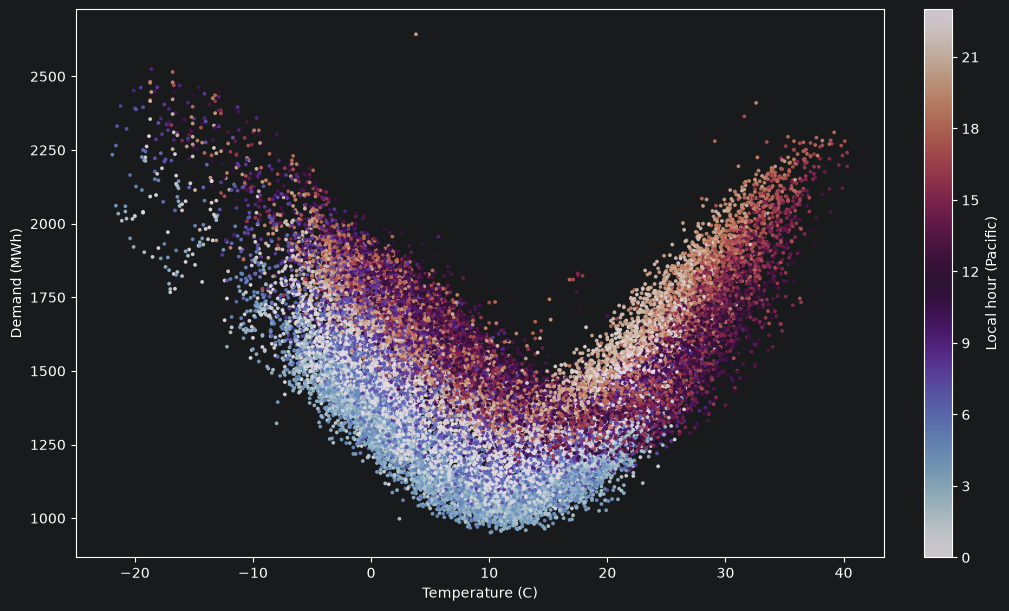

In [1]:
import pandas
from sqlalchemy import text, select, func
import matplotlib.pyplot as plt
from forecast.db.session import get_engine
from forecast.modeling.data import load_demand
from forecast.modeling.cleaning import clean_demand
from forecast import config
from forecast.modeling.data import load_weather

raw_demand = load_demand()
cleaned_demand = clean_demand(raw_demand)
weather = load_weather()
demand_join_weather = cleaned_demand.join(weather[["temp_c"]])
local = demand_join_weather.index.tz_convert("America/Los_Angeles")
demand_join_weather["is_weekend"] = local.day_of_week >=5
demand_join_weather["hour"] = local.hour
plot_data = demand_join_weather[~demand_join_weather["imputed"]]


#Plots the mean demand vs temperature
rounded = plot_data["temp_c"].round()
avg_by_temp = plot_data.groupby(rounded)["clean"].mean()

fig, ax = plt.subplots(figsize = (10,6))
ax.set_xlabel("Temperature (C)")
ax.set_ylabel("Demand (MWh")
ax.plot(avg_by_temp.index, avg_by_temp.values)
plt.show()

#
#

#Plots the mean temperature vs demand overlaid on the scatterplot of temperature vs demand
fig, ax = plt.subplots(figsize = (10,6))
ax.scatter(plot_data["temp_c"], plot_data["clean"], s=4, alpha=.5)
ax.set_xlabel("Temperature (C)")
ax.set_ylabel("Demand (MWh)")
ax.plot(avg_by_temp.index, avg_by_temp.values, color = "red")
plt.show()

#
#

#Plots temperature vs weekend & weekday in demand w/ color mask using scatterplot
weekday = plot_data[~plot_data["is_weekend"]]
weekend = plot_data[plot_data["is_weekend"]]

fig, ax = plt.subplots(figsize = (10,6))
ax.set_xlabel("Temperature (C)")
ax.set_ylabel("Demand (MWh)")
ax.scatter(weekday["temp_c"], weekday["clean"], s= 3, alpha = 0.9, label = "Weekday")
ax.scatter(weekend["temp_c"], weekend["clean"], s= 3, alpha = 0.9, label = "Weekend", color = "red")
ax.legend(loc = "lower center", bbox_to_anchor= (0.5, 1.0), ncol = 2, markerscale = 3)
#Plots means on top of scatterplots for weekend & weekday, along with legend including colors for each element
for name, grp, col in (("Weekday_Mean", weekday, "green"), ("Weekend_mean", weekend, "orange")):
    by_temp = grp.groupby(grp["temp_c"].round())["clean"].mean()
    ax.plot(by_temp.index, by_temp.values, label=name, color = col)
ax.legend(loc = "lower center", bbox_to_anchor= (0.5, 1.0), ncol = 2, markerscale = 3)
plt.show()

#
#

#Plots the temperature vs demand on scatterplot coloring points with color gradient based off of the hour of the day
fig, ax = plt.subplots(figsize = (10,6), layout = "constrained")
ax.set_xlabel("Temperature (C)")
ax.set_ylabel("Demand (MWh)")
sc = ax.scatter(plot_data["temp_c"], plot_data["clean"], s=3, alpha = 0.9, c=plot_data["hour"], cmap = 'twilight')
cbar = fig.colorbar(sc, ax=ax, label="Local hour (Pacific)")
cbar.set_ticks(range(0, 24,3))
plt.show()
